#### библиотеки

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

#### контекст

Компания протестировала новую версию алгоритма рекомендации товаров в пилотном режиме.<br>
Ожидаемая метрика — средний время в приложении . Нам нужно проверить, изменился ли он после запуска.<br>
Коллеги собрали для вас данные пилота в файле *pilot.csv*, в котором есть данные по среднему времени пользователей со старой рекомендательной системой (колонка before), и новой (колонка after)

#### скачиваем данные

In [2]:
pilot_df = pd.read_csv('pilot.csv')
pilot_df.head()

,before,after
0,23.983947,43.674979
1,21.868611,5.216332
2,134.643392,76.246196
3,1.508109,208.595781
4,0.127225,27.954825


#### EDA

In [3]:
pilot_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   before  100 non-null    float64
 1   after   100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


In [4]:
pilot_df.describe()

,before,after
count,100.000000,100.000000
mean,52.332642,62.241794
std,55.847875,54.328672
min,0.127225,1.259207
25%,13.068158,17.392060
50%,38.484174,47.311078
75%,72.176563,100.867460
max,251.988442,214.840553


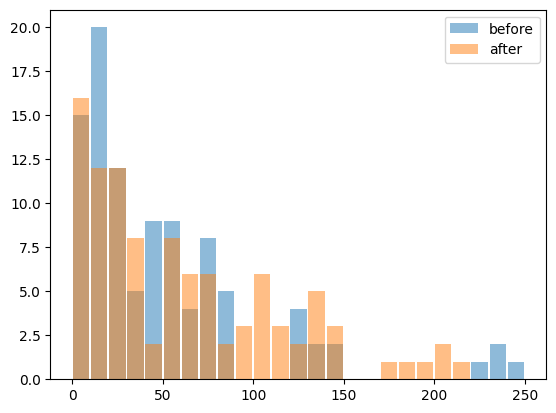

In [6]:
plt.hist(pilot_df['before'], rwidth=0.9, bins=range(0, 260, 10), alpha=0.5, label='before')
plt.hist(pilot_df['after'], rwidth=0.9, bins=range(0, 260, 10), alpha=0.5, label='after')
plt.legend()
plt.show()

#### проверка нормальности

In [7]:
shapiro_before = stats.shapiro(pilot_df['before'])
print("Shapiro-Wilk test p-value (Before):", shapiro_before.pvalue)

Shapiro-Wilk test p-value (Before): 3.7262921914749114e-11


In [8]:
shapiro_after = stats.shapiro(pilot_df['after'])
print("Shapiro-Wilk test p-value (After):", shapiro_after.pvalue)

Shapiro-Wilk test p-value (After): 6.128312861619634e-07


In [9]:
ks_statistic, p_value = stats.kstest(pilot_df['before'], 'norm')
print("Kolmogorov-Smirnov test p-value (Before):", p_value)

Kolmogorov-Smirnov test p-value (Before): 8.403917393489246e-130


In [10]:
ks_statistic, p_value = stats.kstest(pilot_df['after'], 'norm')
print("Kolmogorov-Smirnov test p-value (After):", p_value)

Kolmogorov-Smirnov test p-value (After): 1.444050340613838e-166


#### центральная предельная теорема

In [11]:
mean_before, mean_after = np.mean(pilot_df['before']), np.mean(pilot_df['after'])
std_before, std_after = np.std(pilot_df['before'], ddof=1), np.std(pilot_df['after'], ddof=1)
n_before, n_after = len(pilot_df['before']), len(pilot_df['after'])

In [12]:
#Стандартная ошибка
se = np.sqrt((std_before**2 / n_before) + (std_after**2 / n_after))
#Z-статистика
z_score = (mean_before - mean_after) / se

In [13]:
z_score

-1.2718064736528545

In [14]:
p_value = 1 - stats.norm.cdf(abs(z_score))
print('ЦПТ p_value:', p_value)

ЦПТ p_value: 0.10172094414596677


#### Mann Whiteny U test
так как данные распределены не нормально, и их мало можно применить Mann Whitney тест для проверки стало ли распределение выше (медиана выше) после обновления рек. системы

In [15]:
mann_whitney = stats.mannwhitneyu(pilot_df['before'], pilot_df['after'], alternative='less')
print("Mann-Whitney test p-value:", mann_whitney.pvalue)

Mann-Whitney test p-value: 0.07049129430837435


#### Wilcoxon test
Пришло обновелние от аналитиков: оказывается данные которые мы получили - парные, то есть мы не делили пользователей на А и Б группы, а просто дали одним и тем же пользователям сначала страую систему затем новую и замерили продолжительность пользования в приложении. Для такого случая подходит связанный тест Wilcoxon

In [16]:
stat, p_value = stats.wilcoxon(pilot_df['before'], pilot_df['after'], alternative='less')
print('Wilcoxon p-value:', p_value)

Wilcoxon p-value: 0.04908059745635422
